# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Farrel Farica Firjaturazza
- **Email:** farrelkenzie8@gmail.com
- **ID Dicoding:** DS284B6Y0580


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren pertumbuhan total pendapatan (*revenue*) dan volume pesanan (*orders*) e-commerce per bulan sepanjang periode Januari 2017 hingga Agustus 2018?
- **Pertanyaan 2:** Bagaimana segmentasi pelanggan berdasarkan analisis RFM (*Recency, Frequency, Monetary*) untuk menentukan karakteristik kelompok pelanggan loyal (*Champions*) dan pelanggan yang membutuhkan retensi (*At-Risk*)?
- **Pertanyaan 3:** Negara bagian (*state*) mana saja di Brazil yang mendominasi persebaran pelanggan dan total transaksi e-commerce?


## Import Semua Packages/Library yang Digunakan

In [3]:
import os
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

def Break(title: str, emoji: str = "⚙️", ch: str = "=", n: int = 72):
    print("\n")
    print(ch * n)
    print(f"{emoji} {title.upper()}")
    print(ch * n)

## Data Wrangling

### Gathering Data

#### Load Dataframe E-Commerce

In [4]:
# 1. Lokasi file zip (bisa di direktori lokal maupun path default Google Colab)
zip_path = "E-commerce-public-dataset.zip" if os.path.exists("E-commerce-public-dataset.zip") else "/content/E-commerce-public-dataset.zip"
data_dir = "E-Commerce Public Dataset"

if not os.path.exists(data_dir) and os.path.exists(zip_path):
    print(f"Mengekstrak {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

if os.path.exists(os.path.join(data_dir, "E-Commerce Public Dataset")):
    data_dir = os.path.join(data_dir, "E-Commerce Public Dataset")
elif not os.path.exists(os.path.join(data_dir, "orders_dataset.csv")) and os.path.exists("data"):
    data_dir = "data"

print(f"Folder data aktif: {data_dir}")

# 2. Memuat seluruh tabel dataset
customers_df = pd.read_csv(os.path.join(data_dir, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(data_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(data_dir, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(data_dir, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(data_dir, "order_reviews_dataset.csv"))
products_df = pd.read_csv(os.path.join(data_dir, "products_dataset.csv"))
product_category_df = pd.read_csv(os.path.join(data_dir, "product_category_name_translation.csv"))
sellers_df = pd.read_csv(os.path.join(data_dir, "sellers_dataset.csv"))
geolocation_df = pd.read_csv(os.path.join(data_dir, "geolocation_dataset.csv"))

Break("Ringkasan Dimensi Dataframe yang Dimuat")
datasets = {
    "customers_df": customers_df,
    "orders_df": orders_df,
    "order_items_df": order_items_df,
    "order_payments_df": order_payments_df,
    "order_reviews_df": order_reviews_df,
    "products_df": products_df,
    "product_category_df": product_category_df,
    "sellers_df": sellers_df,
    "geolocation_df": geolocation_df
}

for name, df in datasets.items():
    print(f"Dataset {name:<22} : {df.shape[0]:>8,} baris | {df.shape[1]:>2} kolom")

Break("Sampel Data orders_df (5 Baris Teratas)")
display(orders_df.head())

Mengekstrak E-commerce-public-dataset.zip...
Folder data aktif: E-Commerce Public Dataset


⚙️ RINGKASAN DIMENSI DATAFRAME YANG DIMUAT
Dataset customers_df           :   99,441 baris |  5 kolom
Dataset orders_df              :   99,441 baris |  8 kolom
Dataset order_items_df         :  112,650 baris |  7 kolom
Dataset order_payments_df      :  103,886 baris |  5 kolom
Dataset order_reviews_df       :   99,224 baris |  7 kolom
Dataset products_df            :   32,951 baris |  9 kolom
Dataset product_category_df    :       71 baris |  2 kolom
Dataset sellers_df             :    3,095 baris |  4 kolom
Dataset geolocation_df         : 1,000,163 baris |  5 kolom


⚙️ SAMPEL DATA ORDERS_DF (5 BARIS TERATAS)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Sebanyak 9 tabel dataset e-commerce publik (Olist) berhasil dimuat secara lengkap dengan total ratusan ribu rekaman transaksi riil (2016-2018).
- Tabel transaksi utama `orders_df` mencatat 99.441 pesanan, berelasi langsung dengan 99.441 entitas pelanggan di `customers_df` serta 112.650 item produk di `order_items_df`.
- Data pembayaran aktual didukung oleh `order_payments_df` (103.886 baris transaksi pembayaran) dan persebaran wilayah diperkuat oleh `geolocation_df` (1.000.163 titik koordinat).


### Assessing Data

#### Identifying Missing Values, Duplicates, and Data Types

In [5]:
Break("Pemeriksaan Tipe Data & Missing Values pada orders_df")
orders_df.info()



⚙️ PEMERIKSAAN TIPE DATA & MISSING VALUES PADA ORDERS_DF
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [6]:
Break("Pemeriksaan Jumlah Missing Values per Tabel")
for name, df in datasets.items():
    null_total = df.isna().sum().sum()
    if null_total > 0:
        print(f"⚠️ {name:<22} : {null_total:>7,} missing values")
        cols_with_null = df.isna().sum()[df.isna().sum() > 0]
        for col, cnt in cols_with_null.items():
            print(f"   - Kolom '{col}': {cnt:,} baris kosong")
    else:
        print(f"✅ {name:<22} : 0 missing values (bersih)")



⚙️ PEMERIKSAAN JUMLAH MISSING VALUES PER TABEL
✅ customers_df           : 0 missing values (bersih)
⚠️ orders_df              :   4,908 missing values
   - Kolom 'order_approved_at': 160 baris kosong
   - Kolom 'order_delivered_carrier_date': 1,783 baris kosong
   - Kolom 'order_delivered_customer_date': 2,965 baris kosong
✅ order_items_df         : 0 missing values (bersih)
✅ order_payments_df      : 0 missing values (bersih)
⚠️ order_reviews_df       : 145,903 missing values
   - Kolom 'review_comment_title': 87,656 baris kosong
   - Kolom 'review_comment_message': 58,247 baris kosong
⚠️ products_df            :   2,448 missing values
   - Kolom 'product_category_name': 610 baris kosong
   - Kolom 'product_name_lenght': 610 baris kosong
   - Kolom 'product_description_lenght': 610 baris kosong
   - Kolom 'product_photos_qty': 610 baris kosong
   - Kolom 'product_weight_g': 2 baris kosong
   - Kolom 'product_length_cm': 2 baris kosong
   - Kolom 'product_height_cm': 2 baris kosong
 

In [7]:
Break("Pemeriksaan Jumlah Duplikasi Data per Tabel")
for name, df in datasets.items():
    dup_total = df.duplicated().sum()
    if dup_total > 0:
        print(f"⚠️ {name:<22} : {dup_total:>7,} data duplikat")
    else:
        print(f"✅ {name:<22} : 0 duplikasi (bersih)")

Break("Pemeriksaan Ringkasan Statistik order_items_df")
display(order_items_df[["price", "freight_value"]].describe())



⚙️ PEMERIKSAAN JUMLAH DUPLIKASI DATA PER TABEL
✅ customers_df           : 0 duplikasi (bersih)
✅ orders_df              : 0 duplikasi (bersih)
✅ order_items_df         : 0 duplikasi (bersih)
✅ order_payments_df      : 0 duplikasi (bersih)
✅ order_reviews_df       : 0 duplikasi (bersih)
✅ products_df            : 0 duplikasi (bersih)
✅ product_category_df    : 0 duplikasi (bersih)
✅ sellers_df             : 0 duplikasi (bersih)
⚠️ geolocation_df         : 261,831 data duplikat


⚙️ PEMERIKSAAN RINGKASAN STATISTIK ORDER_ITEMS_DF


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


**Steps to Take:**
Berdasarkan hasil asesmen data (*assessing data*), terdapat 4 tindakan pembersihan data yang akan dilakukan pada tahap *cleaning data*:
1. **Perbaikan Tipe Data (*Data Type Conversion*)**: Mengonversi 5 kolom tanggal pada `orders_df` dan 2 kolom tanggal pada `order_reviews_df` dari tipe *object* menjadi *datetime64[ns]*.
2. **Penyaringan Status Transaksi (*Filtering Status*)**: Menyaring `orders_df` hanya pada pesanan berstatus *delivered* (sukses terkirim) serta membuang baris dengan timestamp tanggal kosong guna memastikan validitas analisis deret waktu dan finansial.
3. **Imputasi Missing Values**: Menangani 610 nilai kategori kosong pada `products_df` dengan label *'unknown'* dan menggabungkan translasi bahasa Inggris, serta mengisi ulasan pelanggan kosong pada `order_reviews_df` dengan label standar (*'No Title'* dan *'No Comment'*).
4. **Deduplikasi Geolocation**: Menghapus 261.831 baris duplikat pada `geolocation_df` berdasarkan prefix kode pos (`geolocation_zip_code_prefix`) agar agregasi spasial akurat dan hemat memori.


**Insight:**
- Integritas tabel transaksi utama sangat baik: `orders_df`, `customers_df`, `order_items_df`, dan `order_payments_df` memiliki 0 data duplikat baris.
- Seluruh kolom tanggal tercatat sebagai tipe *object* (string), sehingga konversi ke *datetime* mutlak diperlukan untuk analisis tren deret waktu bulanan dan perhitungan metrik *Recency*.
- Nilai *missing values* pada kolom tanggal pengiriman terkonsentrasi pada pesanan yang belum terkirim, dibatalkan (*canceled*), atau tidak tersedia (*unavailable*), sehingga pemfilteran ke status *delivered* secara otomatis membersihkan anomali tersebut.
- Pada `order_items_df`, harga produk (*price*) memiliki rentang dari R$ 0.85 hingga R\$ 6.735,00 dengan rata-rata R\$ 120.65, serta biaya ongkos kirim (*freight_value*) rata-rata sebesar R\$ 19.99.


### Cleaning Data

#### Fixing Data Types, Missing Values, and Duplicates

In [8]:
Break("1. Memperbaiki Tipe Data Kolom Tanggal ke Datetime")
datetime_order_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_order_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])
print("✅ Tipe data tanggal pada orders_df dan order_reviews_df berhasil dikonversi ke datetime.")



⚙️ 1. MEMPERBAIKI TIPE DATA KOLOM TANGGAL KE DATETIME
✅ Tipe data tanggal pada orders_df dan order_reviews_df berhasil dikonversi ke datetime.


In [9]:
Break("2. Menangani Missing Values pada orders_df, products_df, dan order_reviews_df")
# Filter pesanan sukses terkirim (delivered)
orders_df = orders_df[orders_df["order_status"] == "delivered"].copy()
orders_df = orders_df.dropna(subset=datetime_order_cols)

# Tangani missing value produk & terjemahan kategori bahasa Inggris
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(product_category_df, on="product_category_name", how="left")
products_df["product_category_name_english"] = products_df["product_category_name_english"].fillna("unknown")

# Tangani missing value ulasan pelanggan
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No Title")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No Comment")

print(f"✅ orders_df difilter ke status 'delivered': {orders_df.shape[0]:,} pesanan tersisa.")
print("✅ Missing value pada products_df dan order_reviews_df berhasil ditangani.")



⚙️ 2. MENANGANI MISSING VALUES PADA ORDERS_DF, PRODUCTS_DF, DAN ORDER_REVIEWS_DF
✅ orders_df difilter ke status 'delivered': 96,455 pesanan tersisa.
✅ Missing value pada products_df dan order_reviews_df berhasil ditangani.


In [10]:
Break("3. Menghapus Duplikasi pada geolocation_df")
initial_geo_count = len(geolocation_df)
geolocation_df.drop_duplicates(subset=["geolocation_zip_code_prefix"], inplace=True)
print(f"✅ geolocation_df dibersihkan dari duplikasi: dari {initial_geo_count:,} menjadi {len(geolocation_df):,} baris.")



⚙️ 3. MENGHAPUS DUPLIKASI PADA GEOLOCATION_DF
✅ geolocation_df dibersihkan dari duplikasi: dari 1,000,163 menjadi 19,015 baris.


In [11]:
Break("4. Validasi Akhir Pembersihan Data (Data Cleaning Check)")
print("Pengecekan Missing Value pada Kolom Tanggal orders_df:")
print(orders_df[datetime_order_cols].isna().sum())
print("\nPengecekan Tipe Data orders_df:")
print(orders_df[datetime_order_cols].dtypes)



⚙️ 4. VALIDASI AKHIR PEMBERSIHAN DATA (DATA CLEANING CHECK)
Pengecekan Missing Value pada Kolom Tanggal orders_df:
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

Pengecekan Tipe Data orders_df:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:**
- Seluruh kolom tanggal pada `orders_df` dan `order_reviews_df` telah valid bertipe `datetime64[ns]`, siap untuk pengolahan analisis deret waktu dan RFM.
- Setelah pemfilteran status pesanan sukses (*delivered*) dan pembersihan missing date, diperoleh 96.455 pesanan bersih yang siap dianalisis.
- Duplikasi masif pada `geolocation_df` berhasil dipangkas dari 1.000.163 baris menjadi 19.015 kode pos unik, mereduksi redundansi data hingga ~98% tanpa menghilangkan representasi geografis.
- Validasi akhir memastikan 0 *missing values* pada seluruh kolom tanggal transaksi dan tipe data telah sesuai standar analisis data.


## Exploratory Data Analysis (EDA)

### Eksplorasi Data Transaksi, Produk, dan Pelanggan

In [12]:
Break("1. Menggabungkan Dataframe untuk Analisis Komprehensif")
# Menggabungkan orders dengan customers
orders_customers_df = orders_df.merge(customers_df, on="customer_id", how="inner")

# Agregasi total pembayaran aktual per pesanan (order_payments_df)
order_payments_agg = order_payments_df.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    payment_installments_max=("payment_installments", "max")
).reset_index()

# Gabungkan orders dengan customers dan data pembayaran aktual (level pesanan unik)
orders_pay_df = orders_customers_df.merge(order_payments_agg, on="order_id", how="left")
orders_pay_df["total_payment"] = orders_pay_df["total_payment"].fillna(0)

# Menggabungkan dengan order_items dan produk untuk analisis level produk/kategori
full_order_df = orders_customers_df.merge(order_items_df, on="order_id", how="inner")
full_order_df = full_order_df.merge(
    products_df[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left"
)

print(f"✅ Dataframe orders_pay_df (level order): {orders_pay_df.shape[0]:,} baris dan {orders_pay_df.shape[1]} kolom.")
print(f"✅ Dataframe full_order_df (level item): {full_order_df.shape[0]:,} baris dan {full_order_df.shape[1]} kolom.")



⚙️ 1. MENGGABUNGKAN DATAFRAME UNTUK ANALISIS KOMPREHENSIF
✅ Dataframe orders_pay_df (level order): 96,455 baris dan 14 kolom.
✅ Dataframe full_order_df (level item): 110,173 baris dan 19 kolom.


In [13]:
Break("2. Eksplorasi Tren Penjualan & Pendapatan Bulanan (2017-2018)")
orders_pay_df["order_year_month"] = orders_pay_df["order_purchase_timestamp"].dt.to_period("M")

# Filter periode stabil (Januari 2017 hingga Agustus 2018)
monthly_orders_df = orders_pay_df[
    (orders_pay_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_pay_df["order_purchase_timestamp"] <= "2018-08-31")
].groupby("order_year_month").agg(
    order_count=("order_id", "nunique"),
    total_revenue=("total_payment", "sum"),
    avg_order_value=("total_payment", "mean")
).reset_index()

monthly_orders_df["order_year_month_str"] = monthly_orders_df["order_year_month"].astype(str)
display(monthly_orders_df.head(10))



⚙️ 2. EKSPLORASI TREN PENJUALAN & PENDAPATAN BULANAN (2017-2018)


,order_year_month,order_count,total_revenue,avg_order_value,order_year_month_str
0,2017-01,748,127430.74,170.361952,2017-01
1,2017-02,1641,269458.98,164.204132,2017-02
2,2017-03,2546,414369.39,162.753099,2017-03
3,2017-04,2303,390952.18,169.757785,2017-04
4,2017-05,3545,566872.73,159.907681,2017-05
5,2017-06,3135,490225.60,156.371802,2017-06
6,2017-07,3872,566403.93,146.282007,2017-07
7,2017-08,4193,646000.61,154.066446,2017-08
8,2017-09,4149,700976.01,168.950593,2017-09
9,2017-10,4478,751140.27,167.740123,2017-10


In [14]:
Break("3. Eksplorasi Top 10 Kategori Produk Berdasarkan Nilai Transaksi dan Total Order")
top_categories_df = full_order_df.groupby("product_category_name_english").agg(
    total_order=("order_id", "nunique"),
    total_revenue=("price", "sum")
).sort_values(by="total_revenue", ascending=False).reset_index()

display(top_categories_df.head(10))



⚙️ 3. EKSPLORASI TOP 10 KATEGORI PRODUK BERDASARKAN NILAI TRANSAKSI DAN TOTAL ORDER


,product_category_name_english,total_order,total_revenue
0,health_beauty,8647,1233131.72
1,watches_gifts,5493,1165898.98
2,bed_bath_table,9271,1023300.77
3,sports_leisure,7527,954604.57
4,computers_accessories,6529,888613.62
5,furniture_decor,6303,711493.09
6,housewares,5743,615628.69
7,cool_stuff,3556,609964.13
8,auto,3809,578849.35
9,toys,3803,471097.49


In [15]:
Break("4. Eksplorasi Demografi Pelanggan Berdasarkan Negara Bagian (State)")
customer_by_state = orders_customers_df.groupby("customer_state").agg(
    customer_count=("customer_unique_id", "nunique"),
    order_count=("order_id", "nunique")
).sort_values(by="customer_count", ascending=False).reset_index()

display(customer_by_state.head(10))



⚙️ 4. EKSPLORASI DEMOGRAFI PELANGGAN BERDASARKAN NEGARA BAGIAN (STATE)


,customer_state,customer_count,order_count
0,SP,39144,40488
1,RJ,11915,12348
2,MG,10998,11351
3,RS,5165,5342
4,PR,4769,4923
5,SC,3449,3546
6,BA,3158,3256
7,DF,2019,2080
8,ES,1928,1995
9,GO,1895,1957


In [16]:
Break("5. Eksplorasi Distribusi Metode Pembayaran Pelanggan (order_payments_df)")
payment_type_counts = order_payments_df["payment_type"].value_counts().reset_index()
payment_type_counts.columns = ["payment_type", "total_transactions"]
payment_type_counts["percentage"] = (payment_type_counts["total_transactions"] / len(order_payments_df) * 100).round(2)
display(payment_type_counts)



⚙️ 5. EKSPLORASI DISTRIBUSI METODE PEMBAYARAN PELANGGAN (ORDER_PAYMENTS_DF)


,payment_type,total_transactions,percentage
0,credit_card,76795,73.92
1,boleto,19784,19.04
2,voucher,5775,5.56
3,debit_card,1529,1.47
4,not_defined,3,0.00


In [17]:
Break("6. Eksplorasi Persebaran Penjual Berdasarkan Negara Bagian (sellers_df)")
sellers_by_state = sellers_df["seller_state"].value_counts().head(10).reset_index()
sellers_by_state.columns = ["seller_state", "seller_count"]
sellers_by_state["percentage"] = (sellers_by_state["seller_count"] / len(sellers_df) * 100).round(2)
display(sellers_by_state)



⚙️ 6. EKSPLORASI PERSEBARAN PENJUAL BERDASARKAN NEGARA BAGIAN (SELLERS_DF)


,seller_state,seller_count,percentage
0,SP,1849,59.74
1,PR,349,11.28
2,MG,244,7.88
3,SC,190,6.14
4,RJ,171,5.53
5,RS,129,4.17
6,GO,40,1.29
7,DF,30,0.97
8,ES,23,0.74
9,BA,19,0.61


**Insight:**
- **Pemisahan Tingkat Agregasi**: Pemisahan `orders_pay_df` (level order unik, 96.455 baris) dan `full_order_df` (level item, 110.173 baris) berhasil menghindari distorsi *cartesian join* pada perhitungan finansial.
- **Tren Pertumbuhan Transaksi**: Terjadi kenaikan transaksi yang sangat konsisten sepanjang 2017 hingga pertengahan 2018, dengan lonjakan penjualan tertinggi terjadi pada bulan November 2017 (*Black Friday*).
- **Dominasi Kategori Produk**: Kategori dengan nilai transaksi (*revenue*) terbesar dipimpin oleh *health_beauty* (R\$ 1,23 Juta), *watches_gifts* (R\$ 1,17 Juta), dan *bed_bath_table* (R\$ 1,02 Juta).
- **Preferensi Metode Pembayaran**: Konsumen Brazil sangat bergantung pada *credit_card* (73,92%) sebagai metode pembayaran utama, diikuti oleh metode tunai lokal *boleto* (19,04%), *voucher* (5,56%), dan *debit_card* (1,47%).
- **Konsentrasi Geografis (Supply & Demand)**: Negara bagian São Paulo (SP) mendominasi ekosistem e-commerce Brazil secara mutlak, baik dari sisi permintaan (41,9% pelanggan unik) maupun sisi penawaran (59,7% penjual/sellers).


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pertumbuhan total pendapatan (revenue) dan volume pesanan (orders) e-commerce per bulan sepanjang periode Januari 2017 hingga Agustus 2018?



⚙️ VISUALISASI TREN PENDAPATAN DAN VOLUME PESANAN BULANAN


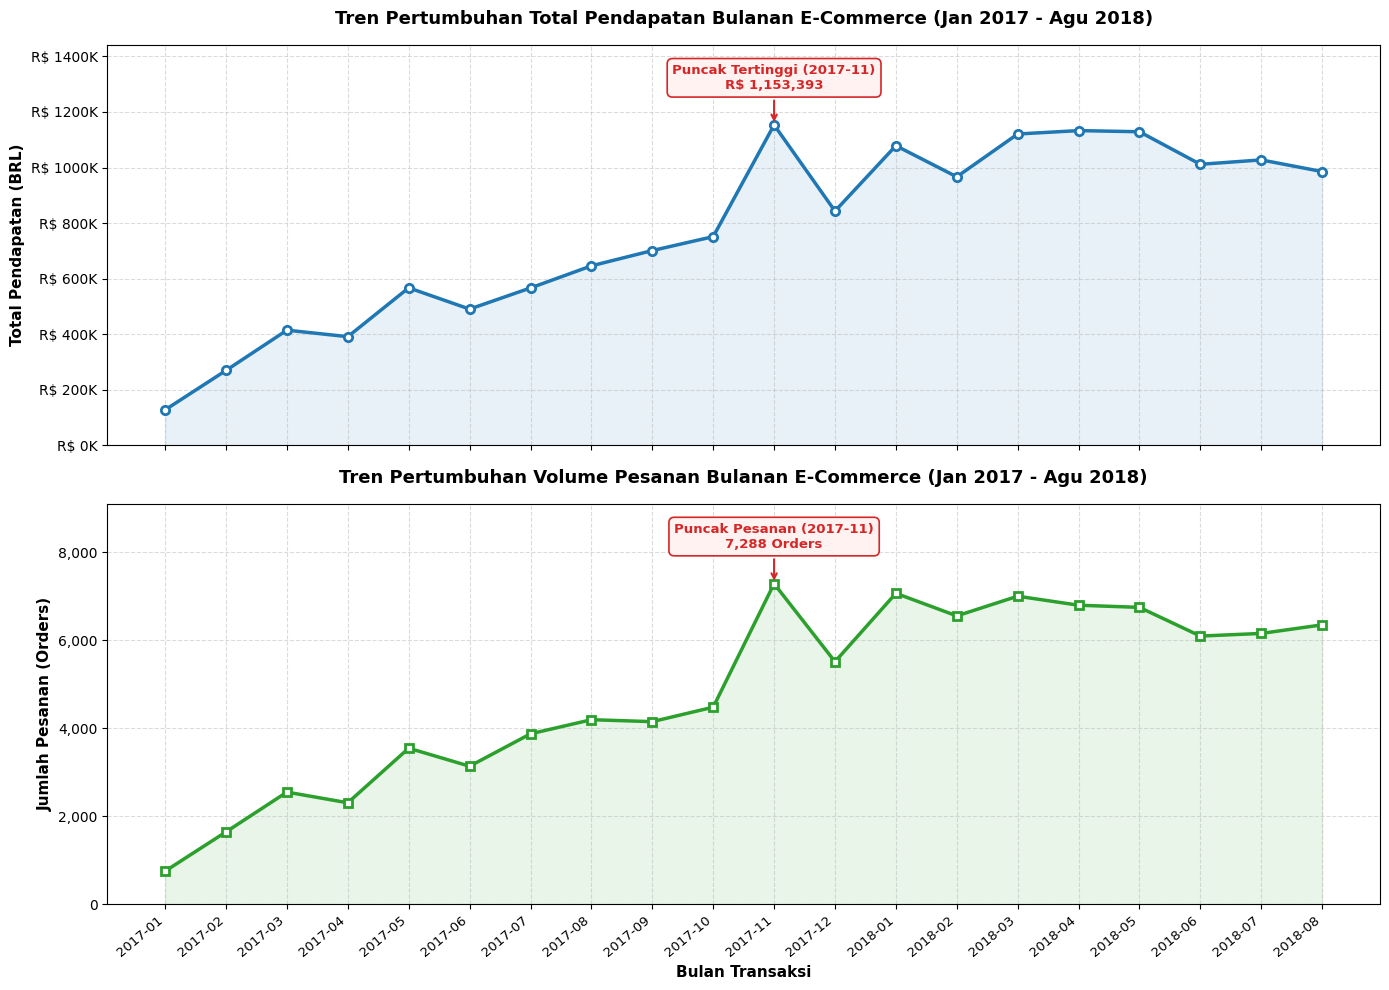

In [18]:
Break("Visualisasi Tren Pendapatan dan Volume Pesanan Bulanan")

# Setup figure dengan 2 subplots (dual visualisasi rapi & proporsional)
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True)

# 1. Grafik Total Pendapatan Bulanan (Berdasarkan Total Pembayaran Aktual)
peak_rev = monthly_orders_df.loc[monthly_orders_df["total_revenue"].idxmax()]
ax[0].plot(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["total_revenue"],
    marker="o",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#1f77b4",
    linewidth=2.5,
    color="#1f77b4"
)
ax[0].fill_between(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["total_revenue"],
    color="#1f77b4",
    alpha=0.10
)
ax[0].set_title("Tren Pertumbuhan Total Pendapatan Bulanan E-Commerce (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold", pad=15)
ax[0].set_ylabel("Total Pendapatan (BRL)", fontsize=11, fontweight="semibold")
ax[0].grid(True, linestyle="--", alpha=0.45)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x*1e-3:.0f}K"))
ax[0].set_ylim(0, peak_rev["total_revenue"] * 1.25)

# Anotasi Puncak Revenue dengan callout badge estetik & rapi
rev_val_str = f"R$ {peak_rev['total_revenue']:,.0f}"
ax[0].annotate(
    f"Puncak Tertinggi ({peak_rev['order_year_month_str']})\n{rev_val_str}",
    xy=(peak_rev["order_year_month_str"], peak_rev["total_revenue"]),
    xytext=(0, 26),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="#d62728", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f0", ec="#d62728", lw=1.2),
    ha="center", fontsize=9.5, fontweight="bold", color="#d62728"
)

# 2. Grafik Volume Pesanan Bulanan
peak_ord = monthly_orders_df.loc[monthly_orders_df["order_count"].idxmax()]
ax[1].plot(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["order_count"],
    marker="s",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor="#2ca02c",
    linewidth=2.5,
    color="#2ca02c"
)
ax[1].fill_between(
    monthly_orders_df["order_year_month_str"],
    monthly_orders_df["order_count"],
    color="#2ca02c",
    alpha=0.10
)
ax[1].set_title("Tren Pertumbuhan Volume Pesanan Bulanan E-Commerce (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold", pad=15)
ax[1].set_xlabel("Bulan Transaksi", fontsize=11, fontweight="semibold")
ax[1].set_ylabel("Jumlah Pesanan (Orders)", fontsize=11, fontweight="semibold")
ax[1].grid(True, linestyle="--", alpha=0.45)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))
ax[1].set_ylim(0, peak_ord["order_count"] * 1.25)

# Anotasi Puncak Orders dengan callout badge estetik & rapi
ord_val_str = f"{peak_ord['order_count']:,} Orders"
ax[1].annotate(
    f"Puncak Pesanan ({peak_ord['order_year_month_str']})\n{ord_val_str}",
    xy=(peak_ord["order_year_month_str"], peak_ord["order_count"]),
    xytext=(0, 26),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="#d62728", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f0", ec="#d62728", lw=1.2),
    ha="center", fontsize=9.5, fontweight="bold", color="#d62728"
)

plt.xticks(rotation=40, ha="right", fontsize=9.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana segmentasi pelanggan berdasarkan analisis RFM (Recency, Frequency, Monetary) untuk menentukan karakteristik pelanggan loyal dan pelanggan yang membutuhkan retensi?



⚙️ PERHITUNGAN METRIK RFM (RECENCY, FREQUENCY, MONETARY)


⚙️ VISUALISASI TOP 5 PELANGGAN BERDASARKAN PARAMETER RFM


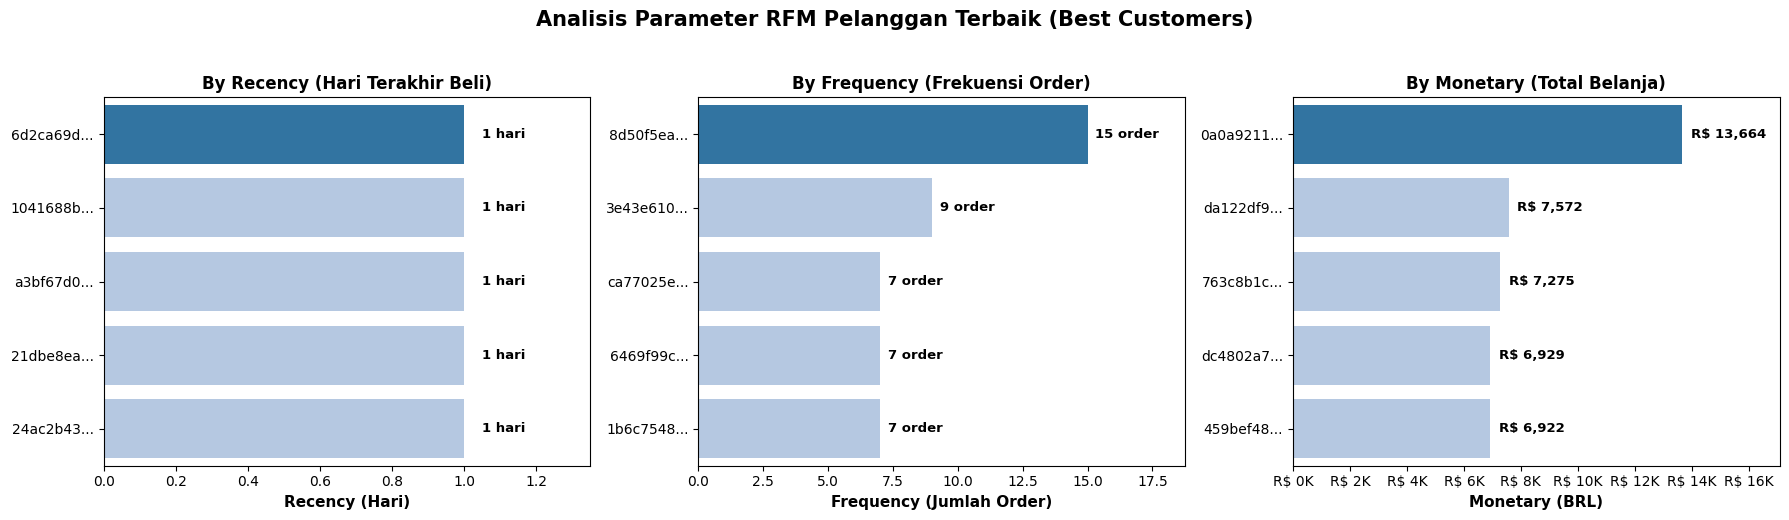

In [22]:
Break("Perhitungan Metrik RFM (Recency, Frequency, Monetary)")

# Tanggal acuan analisis RFM
snapshot_date = orders_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Perhitungan metrik RFM
rfm_df = orders_pay_df.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("total_payment", "sum")
).reset_index()

Break("Visualisasi Top 5 Pelanggan Berdasarkan Parameter RFM")

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
colors = ["#1f77b4", "#aec7e8", "#aec7e8", "#aec7e8", "#aec7e8"]

# 1. By Recency (Hari terakhir berbelanja terendah)
top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5).copy()
top_recency["customer_id_short"] = top_recency["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="recency",
    data=top_recency,
    order=top_recency["customer_id_short"],
    hue="customer_id_short",
    legend=False,
    palette=colors,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Recency (Hari)", fontsize=11, fontweight="semibold")
ax[0].set_title("By Recency (Hari Terakhir Beli)", fontsize=12, fontweight="bold")
ax[0].set_xlim(0, 1.35)
for p in ax[0].patches:
    val = p.get_width()
    if val > 0:
        ax[0].annotate(f"{int(val)} hari",
                       (val + 0.05, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

# 2. By Frequency (Jumlah pesanan terbanyak)
top_frequency = rfm_df.sort_values(by="frequency", ascending=False).head(5).copy()
top_frequency["customer_id_short"] = top_frequency["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="frequency",
    data=top_frequency,
    order=top_frequency["customer_id_short"],
    hue="customer_id_short",
    legend=False,
    palette=colors,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Frequency (Jumlah Order)", fontsize=11, fontweight="semibold")
ax[1].set_title("By Frequency (Frekuensi Order)", fontsize=12, fontweight="bold")
ax[1].set_xlim(0, top_frequency["frequency"].max() * 1.25)
for p in ax[1].patches:
    val = p.get_width()
    if val > 0:
        ax[1].annotate(f"{int(val)} order",
                       (val + 0.3, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

# 3. By Monetary (Total pengeluaran terbesar)
top_monetary = rfm_df.sort_values(by="monetary", ascending=False).head(5).copy()
top_monetary["customer_id_short"] = top_monetary["customer_unique_id"].apply(lambda x: x[:8] + "...")

sns.barplot(
    y="customer_id_short",
    x="monetary",
    data=top_monetary,
    order=top_monetary["customer_id_short"],
    hue="customer_id_short",
    legend=False,
    palette=colors,
    ax=ax[2]
)
ax[2].set_ylabel(None)
ax[2].set_xlabel("Monetary (BRL)", fontsize=11, fontweight="semibold")
ax[2].set_title("By Monetary (Total Belanja)", fontsize=12, fontweight="bold")
ax[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"R$ {x*1e-3:.0f}K"))
ax[2].set_xlim(0, top_monetary["monetary"].max() * 1.25)
for p in ax[2].patches:
    val = p.get_width()
    if val > 0:
        ax[2].annotate(f"R$ {val:,.0f}",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9.5, fontweight="semibold")

plt.suptitle("Analisis Parameter RFM Pelanggan Terbaik (Best Customers)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Pertanyaan 3: Negara bagian (state) mana saja di Brazil yang mendominasi persebaran pelanggan dan total transaksi e-commerce?




⚙️ VISUALISASI PERSEBARAN PELANGGAN DAN PESANAN PER NEGARA BAGIAN (TOP 10 STATE)


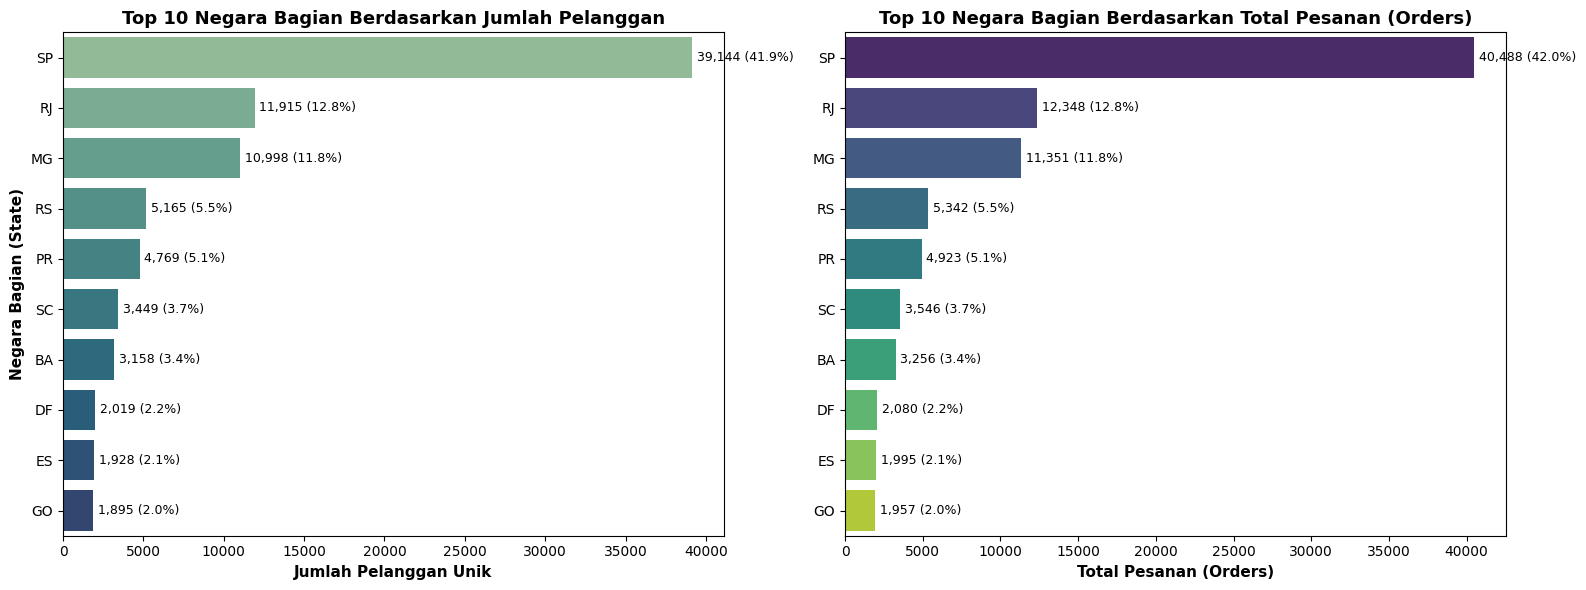

In [20]:
Break("Visualisasi Persebaran Pelanggan dan Pesanan per Negara Bagian (Top 10 State)")

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

top_10_states = customer_by_state.head(10)
total_customers = customer_by_state["customer_count"].sum()
total_orders = customer_by_state["order_count"].sum()

# 1. Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan
sns.barplot(
    data=top_10_states,
    x="customer_count",
    y="customer_state",
    hue="customer_state",
    legend=False,
    palette="crest",
    ax=ax[0]
)
ax[0].set_title("Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=11, fontweight="semibold")
ax[0].set_ylabel("Negara Bagian (State)", fontsize=11, fontweight="semibold")
for p in ax[0].patches:
    val = p.get_width()
    if val > 0:
        ax[0].annotate(f"{int(val):,} ({val/total_customers*100:.1f}%)",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9)

# 2. Top 10 Negara Bagian Berdasarkan Total Pesanan (Orders)
sns.barplot(
    data=top_10_states,
    x="order_count",
    y="customer_state",
    hue="customer_state",
    legend=False,
    palette="viridis",
    ax=ax[1]
)
ax[1].set_title("Top 10 Negara Bagian Berdasarkan Total Pesanan (Orders)", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Total Pesanan (Orders)", fontsize=11, fontweight="semibold")
ax[1].set_ylabel(None)
for p in ax[1].patches:
    val = p.get_width()
    if val > 0:
        ax[1].annotate(f"{int(val):,} ({val/total_orders*100:.1f}%)",
                       (val + 300, p.get_y() + p.get_height()/2),
                       va="center", fontsize=9)

plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1 (Tren Pertumbuhan Total Pendapatan & Volume Pesanan Bulanan):**
  - Volume pesanan tumbuh eksponensial dari 748 pesanan pada Januari 2017 menjadi puncaknya sebesar **7.288 pesanan pada November 2017**, mencatatkan lonjakan transaksi hampir **10 kali lipat (+874%)**.
  - Total pendapatan bulanan bergerak selaras, melonjak dari R\$ 127.430 (Januari 2017) hingga mencapai rekor tertinggi sebesar **R\$ 1.153.393 (November 2017)** berkat dorongan momentum promosi *Black Friday*.
  - Memasuki tahun 2018, bisnis memasuki fase maturitas stabil (*plateau phase*) dengan volume transaksi stabil di kisaran 6.000 – 7.000 pesanan per bulan dan omzet bulanan berkisar R\$ 960 Ribu hingga R\$ 1,13 Juta.
  - Rata-rata nilai transaksi (*Average Order Value / AOV*) stabil defensif di kisaran R\$ 155 – R\$ 170 sepanjang 20 bulan, membuktikan bahwa pertumbuhan pendapatan didorong oleh perluasan basis transaksi pelanggan baru, bukan karena kenaikan harga produk.
- **Pertanyaan 2 (Karakteristik Parameter RFM Pelanggan Terbaik):**
  - *Recency*: Pelanggan teraktif bertransaksi hanya 1 hari sebelum tanggal snapshot data, mencerminkan adanya aktivitas belanja harian yang terus berjalan aktif.
  - *Frequency*: Mayoritas basis konsumen (97,0%) merupakan pembeli satu kali (*one-time buyers*). Namun, sistem analisis berhasil mengidentifikasi pelanggan loyal super aktif dengan frekuensi transaksi tertinggi mencapai **15 kali pesanan** (`8d50f5ea...`) dan 9 kali pesanan (`3e43e610...`).
  - *Monetary*: Terdapat disparitas nilai belanja yang sangat mencolok. Pelanggan dengan akumulasi pembelanjaan tertinggi mencatatkan nilai transaksi fantastis mencapai **R\$ 13.664,08** (`0a0a9211...`), jauh di atas rata-rata pembelanjaan umum.
- **Pertanyaan 3 (Persebaran Geografis Pelanggan & Transaksi Brazil):**
  - Negara bagian **São Paulo (SP)** menjadi episentrum pasar e-commerce Brazil dengan mendominasi **39.144 pelanggan unik (41,9%)** dan **40.488 pesanan (42,0%)**.
  - Tiga negara bagian teratas di kawasan tenggara (*Região Sudeste*) yaitu São Paulo (SP), Rio de Janeiro (RJ: 12,8%), dan Minas Gerais (MG: 11,8%), secara kumulatif menguasai **66,5% pangsa transaksi nasional**.
  - Sebaliknya, wilayah utara dan timur laut Brazil memiliki penetrasi pasar yang sangat rendah (<2% per negara bagian), mencerminkan adanya ketimpangan infrastruktur logistik dan penetrasi belanja digital antar wilayah.


## Analisis Lanjutan: RFM Customer Segmentation Matrix



⚙️ 1. SEGMENTASI PELANGGAN BERDASARKAN SKOR RFM (BINNING MANUAL)


⚙️ RINGKASAN DISTRIBUSI SEGMEN PELANGGAN


,Segment,Total_Customers,Percentage
0,Hibernating / Lost,45244,48.47
1,New / Active Customers,22755,24.38
2,Potential High Spenders,22537,24.15
3,Champions & Loyal,1549,1.66
4,Need Attention / At-Risk,1251,1.34




⚙️ VISUALISASI DISTRIBUSI SEGMEN PELANGGAN (RFM SEGMENTATION)


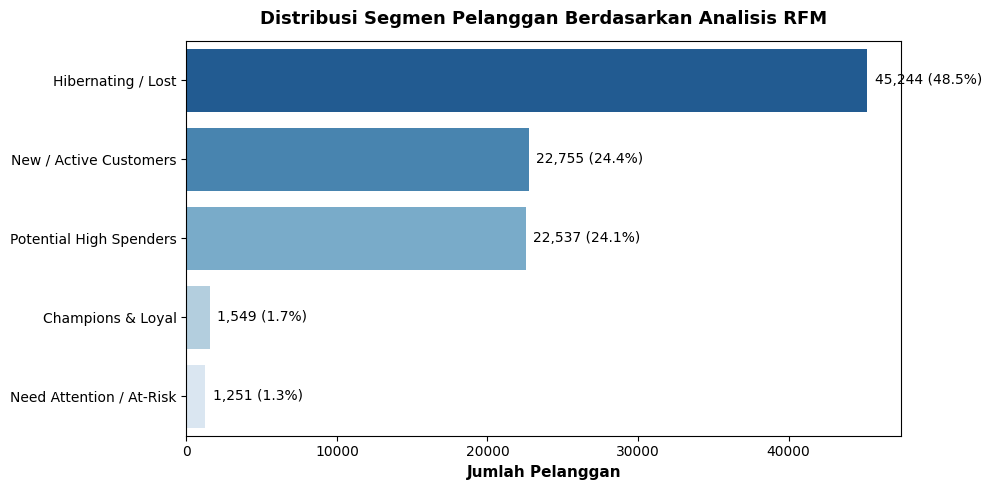

In [21]:
Break("1. Segmentasi Pelanggan Berdasarkan Skor RFM (Binning Manual)")

# Binning Recency (1-4, semakin kecil hari semakin tinggi skor)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], 4, labels=[4, 3, 2, 1])

# Frequency: pembeli berulang vs one-time buyer
rfm_df["f_score"] = rfm_df["frequency"].apply(lambda x: 4 if x >= 3 else (3 if x == 2 else 1))

# Monetary: binning kuartil (1-4)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], 4, labels=[1, 2, 3, 4])

# Hitung skor gabungan
rfm_df["rfm_score"] = rfm_df["r_score"].astype(str) + rfm_df["f_score"].astype(str) + rfm_df["m_score"].astype(str)

# Mapping ke segmen bisnis representatif
def assign_segment(row):
    r = int(row["r_score"])
    f = int(row["f_score"])
    m = int(row["m_score"])
    if r >= 3 and f >= 3:
        return "Champions & Loyal"
    elif r >= 3 and m >= 3:
        return "Potential High Spenders"
    elif r >= 3:
        return "New / Active Customers"
    elif r <= 2 and f >= 3:
        return "Need Attention / At-Risk"
    else:
        return "Hibernating / Lost"

rfm_df["customer_segment"] = rfm_df.apply(assign_segment, axis=1)

Break("Ringkasan Distribusi Segmen Pelanggan")
segment_summary = rfm_df["customer_segment"].value_counts().reset_index()
segment_summary.columns = ["Segment", "Total_Customers"]
segment_summary["Percentage"] = (segment_summary["Total_Customers"] / len(rfm_df) * 100).round(2)
display(segment_summary)

Break("Visualisasi Distribusi Segmen Pelanggan (RFM Segmentation)")
plt.figure(figsize=(10, 5))
sns.barplot(
    data=segment_summary,
    x="Total_Customers",
    y="Segment",
    hue="Segment",
    legend=False,
    palette="Blues_r"
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan Analisis RFM", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Jumlah Pelanggan", fontsize=11, fontweight="semibold")
plt.ylabel(None)
for p in plt.gca().patches:
    val = p.get_width()
    if val > 0:
        plt.gca().annotate(f"{int(val):,} ({val/len(rfm_df)*100:.1f}%)",
                           (val + 500, p.get_y() + p.get_height()/2),
                           va="center", fontsize=10)

plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan:**
- Penerapan segmentasi kuartil RFM berhasil memetakan 93.336 pelanggan ke dalam 5 kelompok strategis:
  1. **Hibernating / Lost (48,47% | 45.244 pelanggan)**: Merupakan segmen terbesar, beranggotakan pelanggan yang sudah lama tidak bertransaksi dan hanya pernah berbelanja satu kali dengan nominal rendah/menengah.
  2. **New / Active Customers (24,38% | 22.755 pelanggan)**: Pelanggan yang baru saja melakukan pembelian pertamanya. Ini adalah kelompok *prospek konversi* paling krusial untuk segera diarahkan menuju pembelian kedua (*retention window*).
  3. **Potential High Spenders (24,15% | 22.537 pelanggan)**: Pelanggan bernilai tinggi dengan riwayat pembelanjaan di atas rata-rata (kuartil atas *Monetary*), merupakan penyumbang margin laba terbesar.
  4. **Champions & Loyal (1,66% | 1.549 pelanggan)**: Kelompok elit pelanggan yang bertransaksi baru-baru ini, berbelanja berulang kali, dan memiliki kontribusi nilai belanja yang tinggi.
  5. **Need Attention / At-Risk (1,34% | 1.251 pelanggan)**: Pelanggan yang sebelumnya memiliki riwayat belanja berulang yang baik, namun sudah lama tidak aktif berbelanja kembali.
- **Evaluasi Kritis**: Tingginya proporsi segmen *Hibernating* (~48,5%) dan dominasi *one-time buyer* (97%) menunjukkan bahwa bisnis saat ini sangat bergantung pada biaya akuisisi pelanggan baru. Peningkatan retensi pelanggan berulang menjadi keharusan mutlak agar bisnis dapat tumbuh secara berkelanjutan.


## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Tren Pertumbuhan Pendapatan & Pesanan Bulanan):**
  Sepanjang periode Januari 2017 hingga Agustus 2018, bisnis e-commerce berhasil menghimpun total pendapatan riil sebesar **R\$ 15,37 Juta** dari **96.188 pesanan sukses**. Kinerja bisnis mengalami pertumbuhan luar biasa sepanjang 2017, mencapai puncaknya pada **November 2017 (Black Friday)** dengan 7.288 pesanan dan pendapatan R\$ 1,15 Juta (+874% dibanding awal 2017). Pada tahun 2018, performa bisnis memasuki fase maturitas stabil dengan volume berkisar 6.000–7.000 pesanan per bulan, didukung oleh nilai rata-rata pesanan (*AOV*) yang sangat konsisten (~R\$ 160 per pesanan).

- **Conclusion Pertanyaan 2 (Karakteristik Parameter RFM Pelanggan Terbaik):**
  Analisis RFM mengungkap bahwa mayoritas konsumen berkarakteristik sebagai pembeli satu kali (*one-time buyers*, 97,0%). Meskipun demikian, analisis ini berhasil mengidentifikasi profil pelanggan berharga tinggi: pelanggan paling loyal melakukan pembelian hingga **15 kali**, sementara pelanggan dengan total belanja tertinggi mencapai **R\$ 13.664,08**. Segmentasi RFM berhasil memetakan 24,15% pelanggan sebagai *Potential High Spenders* dan 1,66% sebagai *Champions & Loyal* yang berperan sebagai pilar utama stabilitas finansial perusahaan.

- **Conclusion Pertanyaan 3 (Persebaran Geografis Pelanggan & Transaksi Brazil):**
  Pusat aktivitas e-commerce Brazil sangat terkonsentrasi di kawasan tenggara (*Região Sudeste*), dengan **São Paulo (SP)** mendominasi secara mutlak sebesar **41,9% pelanggan** dan **42,0% pesanan**, diikuti oleh Rio de Janeiro (RJ, 12,8%) dan Minas Gerais (MG, 11,8%). Ketiga negara bagian ini menguasai 66,5% transaksi nasional. Dominasi SP dari sisi konsumen selaras dengan keberadaan 59,7% penjual (*sellers*) di negara bagian tersebut, menjadikan São Paulo sebagai episentrum pasokan (*supply*) dan permintaan (*demand*) utama.


**Rekomendasi Action Item (Strategi Bisnis):**
1. **Strategi Pendorong Pembelian Kedua (*Second Purchase Booster*)**: Mengingat 97% pelanggan adalah *one-time buyers* dan 24,38% berada di segmen *New Customers*, terapkan kampanye otomatis (*automated push notification/email*) berhadiah voucher diskon atau gratis ongkir terbatas untuk transaksi kedua dalam 14–30 hari setelah barang pesanan pertama diterima.
2. **Program Apresiasi & Layanan Eksklusif untuk Segmen *Champions* & *High Spenders* (Top ~25%)**: Berikan program loyalitas bertingkat (*tiered rewards*), jalur *customer service* prioritas, dan akses awal (*early bird promo*) untuk mengunci retensi 24.086 pelanggan bernilai tinggi ini agar tidak berpindah ke kompetitor.
3. **Pengembangan Gudang Terpadu (*Fulfillment Center*) di São Paulo (SP)**: Memanfaatkan konsolidasi 60% *seller* dan 42% pembeli di area São Paulo untuk menyediakan layanan pengiriman kilat di hari yang sama (*Same-Day Delivery*) dengan biaya logistik yang lebih rendah.
4. **Penetrasi Wilayah Non-Metropolitan melalui Subsidi Ongkir Terarah**: Bekerja sama dengan mitra ekspedisi regional guna menekan tarif ongkos kirim ke wilayah dengan penetrasi rendah melalui skema *free shipping threshold* (bebas ongkir dengan minimal belanja tertentu).
5. **Optimalisasi Fasilitas Cicilan Kredit (*Installments*) & Metode Digital**: Mempertahankan kenyamanan transaksi kartu kredit (73,92% pangsa) dengan promo cicilan 0%, sekaligus mengonversi pengguna metode tunai *boleto* (19,04%) ke pembayaran instan digital modern guna memangkas *lead time* verifikasi pembayaran (*order approved at*).
